In [1]:
# ============================================================
# CELL 1: INSTALL & IMPORT LIBRARIES
# ============================================================
!pip install -q ultralytics albumentations opencv-python-headless imagehash pyyaml seaborn

import os
import cv2
import yaml
import time
import shutil
import random
import hashlib
import zipfile
import json
import threading
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import albumentations as A
from ultralytics import YOLO

print("✅ Installation & Import selesai.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✅ Installation & Import selesai.


In [2]:
# ============================================================
# CELL 2: UPLOAD DATASET ZIP
# ============================================================
from google.colab import files

print("Silakan upload ZIP dataset YOLOv11 kamu:")
uploaded = files.upload()

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]
if not zip_files:
    raise FileNotFoundError("Tidak ada file ZIP yang diupload.")

ZIP_PATH = zip_files[0]
print(f"\n✅ ZIP ditemukan: {ZIP_PATH} ({os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB)")

Silakan upload ZIP dataset YOLOv11 kamu:


Saving crab-partbodyv1.yolov11 (1).zip to crab-partbodyv1.yolov11 (1).zip

✅ ZIP ditemukan: crab-partbodyv1.yolov11 (1).zip (11.58 MB)


In [3]:
# ============================================================
# CELL 3: EXTRACT ZIP & FIND DATA.YAML
# ============================================================
BASE_DIR = Path("/content/crab_raw_dataset")
if BASE_DIR.exists():
    shutil.rmtree(BASE_DIR)
BASE_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(BASE_DIR)

yaml_candidates = list(BASE_DIR.rglob("data.yaml")) + list(BASE_DIR.rglob("data.yml"))
if not yaml_candidates:
    raise FileNotFoundError("data.yaml tidak ditemukan di dalam ZIP.")

DATA_YAML = yaml_candidates[0]
print(f"✅ Dataset diekstrak ke: {BASE_DIR}")
print(f"✅ data.yaml ditemukan : {DATA_YAML}")

✅ Dataset diekstrak ke: /content/crab_raw_dataset
✅ data.yaml ditemukan : /content/crab_raw_dataset/data.yaml


In [4]:
# ============================================================
# CELL 4: READ YAML & CLASS MAPPING
# ============================================================
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

names = data_config.get("names")
if isinstance(names, list):
    CLASS_NAMES = {i: str(name) for i, name in enumerate(names)}
elif isinstance(names, dict):
    CLASS_NAMES = {int(k): str(v) for k, v in names.items()}
else:
    raise ValueError("Format 'names' pada data.yaml tidak dikenali.")

NUM_CLASSES = len(CLASS_NAMES)

print("=== DAFTAR KELAS TERDETEKSI ===")
for cls_id, cls_name in CLASS_NAMES.items():
    print(f"Class {cls_id}: {cls_name}")
print(f"Total Kelas: {NUM_CLASSES}")

=== DAFTAR KELAS TERDETEKSI ===
Class 0: Capit
Class 1: Kaki
Class 2: Kaki Renang
Total Kelas: 3


In [22]:
# ============================================================
# CELL 5: HELPER FUNCTIONS & POLYGON-TO-BBOX CONVERTER
# ============================================================
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_image_files(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

def corresponding_label(image_path):
    image_path = Path(image_path)
    parts = list(image_path.parts)
    if "images" not in parts:
        return None
    idx = parts.index("images")
    label_parts = parts[:]
    label_parts[idx] = "labels"
    return Path(*label_parts).with_suffix(".txt")

def parse_yolo_line_to_bbox(line):
    """
    Membaca 1 baris file .txt YOLO.
    - Jika 5 angka: langsung ambil (cls, x, y, w, h)
    - Jika > 5 angka (Polygon/Segmentation): konversi otomatis ke Bounding Box (cls, x, y, w, h)
    """
    values = line.strip().split()
    if len(values) < 5:
        return None
    try:
        cls = int(float(values[0]))
        coords = [float(v) for v in values[1:]]
    except Exception:
        return None

    if len(coords) == 4:
        x, y, w, h = coords
    elif len(coords) >= 6 and len(coords) % 2 == 0:
        # Format Polygon (x1, y1, x2, y2, ...): cari titik paling luar
        xs = coords[0::2]
        ys = coords[1::2]
        x_min, x_max = max(0.0, min(xs)), min(1.0, max(xs))
        y_min, y_max = max(0.0, min(ys)), min(1.0, max(ys))
        w = x_max - x_min
        h = y_max - y_min
        x = x_min + (w / 2.0)
        y = y_min + (h / 2.0)
    else:
        return None

    # Clamp agar berada di rentang 0.0 - 1.0 dan pastikan box tidak terpotong keluar batas
    x = max(0.0, min(1.0, x))
    y = max(0.0, min(1.0, y))
    w = max(0.0, min(1.0, w))
    h = max(0.0, min(1.0, h))

    if w <= 0.001 or h <= 0.001:
        return None

    return cls, x, y, w, h

def read_yolo_labels(label_path):
    labels = []
    if label_path is None or not label_path.exists():
        return labels
    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parsed = parse_yolo_line_to_bbox(line)
            if parsed is not None:
                labels.append(parsed[0])
    return labels

def find_split_dir(split_names):
    candidates = []
    for name in split_names:
        for p in BASE_DIR.rglob(name):
            if p.is_dir() and (p / "images").is_dir() and (p / "labels").is_dir():
                candidates.append(p)
    if not candidates:
        return None
    return max(candidates, key=lambda p: len(get_image_files(p / "images")))

RAW_SPLITS = {
    "train": find_split_dir(["train"]),
    "val": find_split_dir(["valid", "val", "validation"]),
    "test": find_split_dir(["test"]),
}

for split, path in RAW_SPLITS.items():
    print(f"{split:5s}: {path}")

train: /content/crab_raw_dataset/train
val  : /content/crab_raw_dataset/valid
test : /content/crab_raw_dataset/test


In [24]:
# ============================================================
# CELL 6: INITIAL DATASET AUDIT
# ============================================================
def analyze_split(split_path):
    if split_path is None or not Path(split_path).exists():
        return None
    images = get_image_files(Path(split_path) / "images")
    class_annotations = Counter()
    class_images = Counter()
    missing_labels = []

    for image_path in images:
        label_path = corresponding_label(image_path)
        labels = read_yolo_labels(label_path)
        if not labels:
            missing_labels.append(image_path)
        for cls in labels:
            class_annotations[cls] += 1
        for cls in set(labels):
            class_images[cls] += 1

    return {
        "images": images,
        "image_count": len(images),
        "annotations": class_annotations,
        "class_images": class_images,
        "missing_labels": missing_labels,
    }

print("=== DISTRIBUSI DATASET AWAL ===")
for split, path in RAW_SPLITS.items():
    if path is None:
        continue
    res = analyze_split(path)
    print(f"\n[{split.upper()}] Total Gambar: {res['image_count']}")
    for cid in range(NUM_CLASSES):
        print(f"  - {CLASS_NAMES[cid]:20s}: {res['class_images'][cid]:4d} imgs | {res['annotations'][cid]:5d} bboxes")

=== DISTRIBUSI DATASET AWAL ===

[TRAIN] Total Gambar: 41
  - Capit               :   41 imgs |    82 bboxes
  - Kaki                :   41 imgs |   234 bboxes
  - Kaki Renang         :   41 imgs |    77 bboxes

[VAL] Total Gambar: 11
  - Capit               :   11 imgs |    22 bboxes
  - Kaki                :   11 imgs |    65 bboxes
  - Kaki Renang         :   11 imgs |    22 bboxes

[TEST] Total Gambar: 10
  - Capit               :   10 imgs |    20 bboxes
  - Kaki                :   10 imgs |    60 bboxes
  - Kaki Renang         :   10 imgs |    20 bboxes


In [25]:
# ============================================================
# CELL 7: DEDUPLICATE & ROBUST MULTI-LABEL SPLIT
# ============================================================
def calculate_phash(path):
    try:
        return imagehash.phash(Image.open(path).convert("RGB"))
    except Exception:
        return None

# 1. Kumpulkan semua gambar berlabel yang valid & buang duplikat identik (distance == 0)
all_raw_images = []
for split_name, split_dir in RAW_SPLITS.items():
    if split_dir is not None:
        all_raw_images.extend(get_image_files(split_dir / "images"))

clean_images = []
seen_hashes = []

for img_path in all_raw_images:
    # Abaikan file sisa augmentasi kita sendiri jika ada
    if "_aug_cls" in img_path.name:
        continue
    lbl_path = corresponding_label(img_path)
    lbls = read_yolo_labels(lbl_path)
    if not lbls:
        continue

    h = calculate_phash(img_path)
    if h is None:
        continue

    # Hanya buang jika benar-benar kembar identik (distance <= 1) agar data asli tidak habis
    if any((h - sh) <= 1 for sh in seen_hashes):
        continue

    seen_hashes.append(h)
    clean_images.append(img_path)

print(f"✅ Total gambar unik berlabel yang terkumpul: {len(clean_images)}")

# 2. Siapkan folder bersih
CLEAN_ROOT = Path("/content/crab_clean_split")
if CLEAN_ROOT.exists():
    shutil.rmtree(CLEAN_ROOT)

for s in ["train", "valid", "test"]:
    (CLEAN_ROOT / s / "images").mkdir(parents=True, exist_ok=True)
    (CLEAN_ROOT / s / "labels").mkdir(parents=True, exist_ok=True)

# 3. Pembagian proporsional (75% Train, 15% Val, 10% Test) dengan jaminan semua kelas ada di Val
random.seed(42)
shuffled_imgs = clean_images[:]
random.shuffle(shuffled_imgs)

total_n = len(shuffled_imgs)
n_val = max(int(total_n * 0.15), 25)   # Minimal 25 gambar di Val (atau 15% dari total)
n_test = max(int(total_n * 0.10), 15)  # Minimal 15 gambar di Test (atau 10% dari total)

# Jika dataset sangat kecil (< 100 gambar), sesuaikan otomatis
if total_n < 100:
    n_val = max(int(total_n * 0.20), 15)
    n_test = max(int(total_n * 0.10), 8)

val_imgs = shuffled_imgs[:n_val]
test_imgs = shuffled_imgs[n_val:n_val + n_test]
train_imgs = shuffled_imgs[n_val + n_test:]

# Pastikan setiap kelas memiliki minimal beberapa sampel di Val; jika ada kelas yang 0 di Val, pindahkan sebagian dari Train
for cid in range(NUM_CLASSES):
    val_cls_count = sum(1 for img in val_imgs if cid in read_yolo_labels(corresponding_label(img)))
    if val_cls_count < 5:
        candidates = [img for img in train_imgs if cid in read_yolo_labels(corresponding_label(img))]
        move_n = min(5 - val_cls_count, max(0, len(candidates) // 3))
        for img_to_move in candidates[:move_n]:
            train_imgs.remove(img_to_move)
            val_imgs.append(img_to_move)

def copy_to_split(img_list, split_folder):
    for idx, img in enumerate(img_list):
        lbl = corresponding_label(img)
        if lbl and lbl.exists():
            # Beri nama unik agar tidak tertimpa jika ada nama file sama dari folder berbeda
            new_stem = f"img_{idx:04d}_{img.stem}"
            shutil.copy2(img, CLEAN_ROOT / split_folder / "images" / f"{new_stem}{img.suffix}")
            shutil.copy2(lbl, CLEAN_ROOT / split_folder / "labels" / f"{new_stem}.txt")

copy_to_split(train_imgs, "train")
copy_to_split(val_imgs, "valid")
copy_to_split(test_imgs, "test")

SPLITS = {
    "train": CLEAN_ROOT / "train",
    "val": CLEAN_ROOT / "valid",
    "test": CLEAN_ROOT / "test",
}

print("\n=== DISTRIBUSI BARU SETELAH RE-SPLIT PROPORSIONAL ===")
for split, path in SPLITS.items():
    res = analyze_split(path)
    print(f"\n[{split.upper()}] Total Gambar: {res['image_count']}")
    for cid in range(NUM_CLASSES):
        print(f"  - {CLASS_NAMES[cid]:20s}: {res['class_images'][cid]:4d} imgs | {res['annotations'][cid]:5d} bboxes")

✅ Total gambar unik berlabel yang terkumpul: 62

=== DISTRIBUSI BARU SETELAH RE-SPLIT PROPORSIONAL ===

[TRAIN] Total Gambar: 39
  - Capit               :   39 imgs |    78 bboxes
  - Kaki                :   39 imgs |   225 bboxes
  - Kaki Renang         :   39 imgs |    75 bboxes

[VAL] Total Gambar: 15
  - Capit               :   15 imgs |    30 bboxes
  - Kaki                :   15 imgs |    87 bboxes
  - Kaki Renang         :   15 imgs |    29 bboxes

[TEST] Total Gambar: 8
  - Capit               :    8 imgs |    16 bboxes
  - Kaki                :    8 imgs |    47 bboxes
  - Kaki Renang         :    8 imgs |    15 bboxes


In [26]:
# ============================================================
# CELL 8: SMART AUGMENTATION PIPELINE CONFIG
# ============================================================
TARGET_IMAGES_PER_CLASS = 500
TARGET_ANNOTATIONS_PER_CLASS = 1500

TARGETS_BY_CLASS_NAME = {
    cls_name: TARGET_IMAGES_PER_CLASS
    for cls_id, cls_name in CLASS_NAMES.items()
}

# Pipeline aman untuk Bounding Box YOLO (Tanpa rotasi miring yang merusak koordinat)
augmentation = A.Compose(
    [
        A.HorizontalFlip(p=0.50),
        A.VerticalFlip(p=0.50),
        A.RandomRotate90(p=0.50),

        # Zoom In/Out & Pergeseran posisi tanpa memiringkan kotak
        A.Affine(
            scale=(0.80, 1.15),
            translate_percent=(-0.06, 0.06),
            rotate=0,
            shear=0,
            border_mode=cv2.BORDER_REFLECT_101,
            p=0.45
        ),

        # Variasi Warna & Pencahayaan agar kuat mendeteksi kepiting warna merah/hijau/coklat
        A.HueSaturationValue(
            hue_shift_limit=15,
            sat_shift_limit=25,
            val_shift_limit=20,
            p=0.35
        ),

        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=0.35
        ),
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"],
        min_visibility=0.35,
        clip=True
    )
)

print("✅ Pipeline Augmentasi siap.")

✅ Pipeline Augmentasi siap.


In [27]:
# ============================================================
# CELL 9: YOLO AUGMENTATION HELPER FUNCTIONS (SAFE BBOX & POLYGON)
# ============================================================
def load_yolo_annotation(label_path):
    bboxes = []
    class_labels = []
    if label_path is None or not label_path.exists():
        return bboxes, class_labels

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parsed = parse_yolo_line_to_bbox(line)
            if parsed is not None:
                cls, x, y, w, h = parsed
                # Pastikan x_min, y_min, x_max, y_max valid untuk Albumentations
                x_min = max(0.0, x - w / 2.0)
                y_min = max(0.0, y - h / 2.0)
                x_max = min(1.0, x + w / 2.0)
                y_max = min(1.0, y + h / 2.0)
                new_w = x_max - x_min
                new_h = y_max - y_min
                new_x = x_min + new_w / 2.0
                new_y = y_min + new_h / 2.0
                if new_w > 0.002 and new_h > 0.002:
                    bboxes.append([new_x, new_y, new_w, new_h])
                    class_labels.append(int(cls))
    return bboxes, class_labels

def save_yolo_annotation(label_path, bboxes, class_labels):
    with open(label_path, "w", encoding="utf-8") as f:
        for bbox, cls in zip(bboxes, class_labels):
            x, y, w, h = bbox
            x = min(max(float(x), 0.0), 1.0)
            y = min(max(float(y), 0.0), 1.0)
            w = min(max(float(w), 0.0), 1.0)
            h = min(max(float(h), 0.0), 1.0)
            if w <= 0.001 or h <= 0.001:
                continue
            f.write(f"{int(cls)} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

def augment_yolo_image(image_path, output_image_path, output_label_path):
    image = cv2.imread(str(image_path))
    if image is None:
        return False
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    label_path = corresponding_label(image_path)
    bboxes, class_labels = load_yolo_annotation(label_path)
    if not bboxes:
        return False

    try:
        transformed = augmentation(
            image=image,
            bboxes=bboxes,
            class_labels=class_labels
        )
    except Exception as e:
        return False

    new_image = transformed["image"]
    new_bboxes = transformed["bboxes"]
    new_labels = transformed["class_labels"]

    # JANGAN SIMPAN gambar jika bounding box hilang setelah transformasi!
    if not new_bboxes or len(new_bboxes) == 0:
        return False

    new_image = cv2.cvtColor(new_image, cv2.COLOR_RGB2BGR)
    if not cv2.imwrite(str(output_image_path), new_image):
        return False

    save_yolo_annotation(output_label_path, new_bboxes, new_labels)
    return output_label_path.exists()

print("✅ Fungsi penyimpanan anotasi YOLO (Anti-Hilang BBox) siap.")

✅ Fungsi penyimpanan anotasi YOLO (Anti-Hilang BBox) siap.


In [28]:
# ============================================================
# CELL 10: EXECUTE AUGMENTATION ON TRAIN SPLIT
# ============================================================
train_path = SPLITS["train"]
train_images_dir = train_path / "images"
train_labels_dir = train_path / "labels"

original_train_images = [
    p for p in get_image_files(train_images_dir)
    if "_aug_cls" not in p.stem
]

def get_images_containing_class(class_id, image_files):
    return [
        img for img in image_files
        if class_id in read_yolo_labels(corresponding_label(img))
    ]

sorted_class_ids = sorted(
    CLASS_NAMES.keys(),
    key=lambda cid: len(get_images_containing_class(cid, original_train_images))
)

augmentation_summary = []

for class_id in sorted_class_ids:
    requested_name = CLASS_NAMES[class_id]
    raw_target = TARGETS_BY_CLASS_NAME[requested_name]

    source_images = get_images_containing_class(class_id, original_train_images)
    orig_count = len(source_images)

    # Batas aman: maksimal digandakan 10x dari jumlah asli agar tidak overfitting
    effective_target = min(raw_target, max(orig_count * 10, orig_count))

    all_current_train_images = get_image_files(train_images_dir)
    current_count = len(get_images_containing_class(class_id, all_current_train_images))

    needed = max(0, effective_target - current_count)
    created = 0
    attempts = 0
    max_attempts = max(needed * 12, 50)

    while created < needed and attempts < max_attempts and orig_count > 0:
        attempts += 1
        source = random.choice(source_images)
        output_name = f"{source.stem}_aug_cls{class_id}_{created:05d}.jpg"
        output_image = train_images_dir / output_name
        output_label = train_labels_dir / output_name.replace(".jpg", ".txt")

        if output_image.exists():
            continue

        if augment_yolo_image(source, output_image, output_label):
            created += 1

    final_count = len(get_images_containing_class(class_id, get_image_files(train_images_dir)))
    augmentation_summary.append({
        "class_id": class_id,
        "class": requested_name,
        "orig_train": orig_count,
        "before_loop": current_count,
        "created": created,
        "final_train": final_count
    })

display(pd.DataFrame(augmentation_summary))

,class_id,class,orig_train,before_loop,created,final_train
0,0,Capit,39,39,351,390
1,1,Kaki,39,390,0,390
2,2,Kaki Renang,39,390,0,390


,class_id,class,train_images,train_bboxes,val_images,val_bboxes
0,0,Capit,390,780,15,30
1,1,Kaki,390,2263,15,87
2,2,Kaki Renang,390,753,15,29


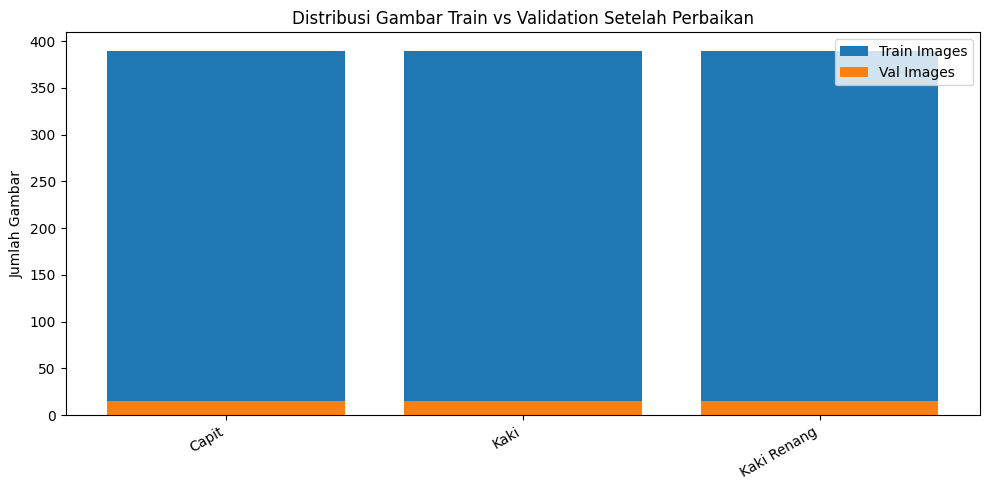

In [29]:
# ============================================================
# CELL 11: CHECK FINAL DISTRIBUTION & PLOT
# ============================================================
train_analysis_after = analyze_split(SPLITS["train"])
val_analysis_after = analyze_split(SPLITS["val"])

rows = []
for cls_id, cls_name in CLASS_NAMES.items():
    rows.append({
        "class_id": cls_id,
        "class": cls_name,
        "train_images": train_analysis_after["class_images"][cls_id],
        "train_bboxes": train_analysis_after["annotations"][cls_id],
        "val_images": val_analysis_after["class_images"][cls_id],
        "val_bboxes": val_analysis_after["annotations"][cls_id],
    })

df_after = pd.DataFrame(rows)
display(df_after)

plt.figure(figsize=(10, 5))
plt.bar(df_after["class"], df_after["train_images"], label="Train Images")
plt.bar(df_after["class"], df_after["val_images"], label="Val Images")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Jumlah Gambar")
plt.title("Distribusi Gambar Train vs Validation Setelah Perbaikan")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# CELL 12: BUILD ULTRALYTICS EXPORT DATASET
# ============================================================
EXPORT_ROOT = Path("/content/crab_ready_dataset")
if EXPORT_ROOT.exists():
    shutil.rmtree(EXPORT_ROOT)
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)

for split_name in ["train", "val", "test"]:
    source = SPLITS.get(split_name)
    if source is None:
        continue
    dest_name = "valid" if split_name == "val" else split_name
    shutil.copytree(source, EXPORT_ROOT / dest_name)

export_config = {
    "path": str(EXPORT_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": NUM_CLASSES,
    "names": {int(k): v for k, v in CLASS_NAMES.items()}
}

EXPORT_YAML = EXPORT_ROOT / "data.yaml"
with open(EXPORT_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(export_config, f, sort_keys=False, allow_unicode=True)

print("✅ Export YAML berhasil dibuat:")
print(EXPORT_YAML.read_text(encoding="utf-8"))

✅ Export YAML berhasil dibuat:
path: /content/crab_ready_dataset
train: train/images
val: valid/images
test: test/images
nc: 3
names:
  0: Capit
  1: Kaki
  2: Kaki Renang



In [31]:
# ============================================================
# CELL 13: CONVERT POLYGONS, VALIDATE LABELS & REMOVE EMPTY IMAGES
# ============================================================
def validate_and_fix_dataset(split_dir, num_classes):
    images_dir = Path(split_dir) / "images"
    labels_dir = Path(split_dir) / "labels"

    total_valid_boxes = 0
    converted_or_clamped = 0
    removed_empty_images = 0

    for img_path in get_image_files(images_dir):
        lbl_path = labels_dir / f"{img_path.stem}.txt"
        if not lbl_path.exists():
            img_path.unlink(missing_ok=True)
            removed_empty_images += 1
            continue

        valid_lines = []
        changed = False

        with open(lbl_path, "r", encoding="utf-8") as f:
            for line in f:
                raw_vals = line.strip().split()
                parsed = parse_yolo_line_to_bbox(line)
                if parsed is None:
                    changed = True
                    continue
                cls, x, y, w, h = parsed
                if not (0 <= cls < num_classes):
                    changed = True
                    continue

                # Jika aslinya poligon (>5 angka), tandai bahwa berhasil dikonversi ke BBox
                if len(raw_vals) != 5:
                    changed = True
                    converted_or_clamped += 1

                valid_lines.append(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
                total_valid_boxes += 1

        # Jika setelah dicek ternyata tidak ada bounding box sama sekali, HAPUS gambar & labelnya
        # supaya tidak meracuni model sebagai false background!
        if len(valid_lines) == 0:
            lbl_path.unlink(missing_ok=True)
            img_path.unlink(missing_ok=True)
            removed_empty_images += 1
        elif changed:
            with open(lbl_path, "w", encoding="utf-8") as f:
                f.writelines(valid_lines)

    return total_valid_boxes, converted_or_clamped, removed_empty_images

for sp in ["train", "valid", "test"]:
    sp_path = EXPORT_ROOT / sp
    if sp_path.exists():
        boxes, conv, rem = validate_and_fix_dataset(sp_path, NUM_CLASSES)
        imgs_left = len(get_image_files(sp_path / "images"))
        print(f"[{sp.upper():5s}] Gambar tersisa: {imgs_left:4d} | Total BBox: {boxes:5d} | Dikonversi/Diperbaiki: {conv:4d} | Gambar Kosong Dihapus: {rem:3d}")

print("\n✅ Semua gambar dijamin memiliki Bounding Box utuh!")

[TRAIN] Gambar tersisa:  390 | Total BBox:  3796 | Dikonversi/Diperbaiki:  310 | Gambar Kosong Dihapus:   0
[VALID] Gambar tersisa:   15 | Total BBox:   146 | Dikonversi/Diperbaiki:  120 | Gambar Kosong Dihapus:   0
[TEST ] Gambar tersisa:    8 | Total BBox:    78 | Dikonversi/Diperbaiki:   70 | Gambar Kosong Dihapus:   0

✅ Semua gambar dijamin memiliki Bounding Box utuh!


In [32]:
# ============================================================
# CELL 14: ZIP & DOWNLOAD DATASET (UNTUK ULTRALYTICS CLOUD)
# ============================================================
DATASET_ZIP_OUT = "/content/crab_ready_dataset.zip"
if os.path.exists(DATASET_ZIP_OUT):
    os.remove(DATASET_ZIP_OUT)

shutil.make_archive(
    "/content/crab_ready_dataset",
    "zip",
    root_dir="/content",
    base_dir="crab_ready_dataset"
)

size_mb = os.path.getsize(DATASET_ZIP_OUT) / (1024**2)
print(f"✅ ZIP siap: {DATASET_ZIP_OUT} ({size_mb:.2f} MB)")

from google.colab import files
files.download(DATASET_ZIP_OUT)

✅ ZIP siap: /content/crab_ready_dataset.zip (93.17 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# ============================================================
# CELL 15: TRAIN YOLOv11 MODEL
# ============================================================
# Gunakan yolo11s.pt (cepat untuk streaming) atau yolo11m.pt (akurasi ekstra)
MODEL_NAME = "yolo11s.pt"
model = YOLO(MODEL_NAME)

results = model.train(
    data=str(EXPORT_YAML),
    epochs=100,
    imgsz=640,          # Optimal untuk kecepatan kamera streaming & bagian tubuh
    batch=16,
    patience=30,
    device=0,
    workers=2,

    pretrained=True,
    optimizer="AdamW",  # Mencegah grafik loss naik-turun ekstrem
    lr0=0.001,          # Learning rate stabil untuk AdamW
    lrf=0.01,
    cos_lr=True,        # Memaksimalkan mAP50-95 di akhir epoch
    weight_decay=0.0005,
    amp=True,

    # Pengaturan Augmentasi On-The-Fly yang seimbang
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.3,
    degrees=0.0,        # Jaga agar kotak tidak melar
    translate=0.05,
    scale=0.3,
    shear=0.0,
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    erasing=0.0,        # Matikan random erasing agar organ tidak hilang
    close_mosaic=20,    # Matikan mosaic 20 epoch terakhir untuk merapatkan bbox

    project="/content/crab_runs",
    name="crab_model_final",
    exist_ok=True,
    plots=True,
    verbose=True
)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/crab_ready_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=crab_model_final, nbs=64, nms=None, opset=None, opt

In [34]:
# ============================================================
# CELL 16: VALIDATE BEST MODEL & EXPORT ONNX
# ============================================================
RUN_DIR = Path("/content/crab_runs/crab_model_final")
BEST_PT = RUN_DIR / "weights" / "best.pt"

if not BEST_PT.exists():
    raise FileNotFoundError(f"best.pt tidak ditemukan di {BEST_PT}")

best_model = YOLO(str(BEST_PT))

# Evaluasi pada Validation Set (Tanpa memotong conf_threshold agar kurva mAP akurat)
val_metrics = best_model.val(
    data=str(EXPORT_YAML),
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("\n" + "=" * 55)
print("FINAL VALIDATION METRICS")
print("=" * 55)
print(f"Precision : {val_metrics.box.mp:.4f} ({val_metrics.box.mp*100:.1f}%)")
print(f"Recall    : {val_metrics.box.mr:.4f} ({val_metrics.box.mr*100:.1f}%)")
print(f"mAP50     : {val_metrics.box.map50:.4f} ({val_metrics.box.map50*100:.1f}%)")
print(f"mAP50-95  : {val_metrics.box.map:.4f} ({val_metrics.box.map*100:.1f}%)")

# Export ke format ONNX untuk deployment streaming cepat
onnx_path = best_model.export(format="onnx", imgsz=640, simplify=True)
print(f"\n✅ Model Terbaik (PyTorch): {BEST_PT}")
print(f"✅ Model Terbaik (ONNX)   : {onnx_path}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2426.1±1000.5 MB/s, size: 186.9 KB)
val: Scanning /content/crab_ready_dataset/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 3.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.4it/s 0.4s
                   all         15        146      0.995      0.996      0.992      0.886
                 Capit         15         30      0.993          1      0.995      0.853
                  Kaki         15         87      0.999      0.989      0.985      0.854
           Kaki Renang         15         29      0.995          1      0.995      0.953
Speed: 0.4ms preprocess, 13.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val-2

In [35]:
# ============================================================
# DOWNLOAD MODEL WEIGHTS & ASSETS DARI COLAB
# ============================================================
import shutil
from pathlib import Path
from google.colab import files

RUN_DIR = Path("/content/crab_runs/crab_model_final")
EXPORT_DIR = Path("/content/crab_model_download")

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Salin bobot model (best.pt dan best.onnx)
best_pt = RUN_DIR / "weights" / "best.pt"
best_onnx = RUN_DIR / "weights" / "best.onnx"

if best_pt.exists():
    shutil.copy2(best_pt, EXPORT_DIR / "best.pt")
if best_onnx.exists():
    shutil.copy2(best_onnx, EXPORT_DIR / "best.onnx")

# 2. Salin grafik hasil evaluasi (confusion matrix, PR curve, dll)
for img_metric in RUN_DIR.glob("*.png"):
    shutil.copy2(img_metric, EXPORT_DIR / img_metric.name)

# 3. Zip dan unduh ke laptop
ZIP_OUTPUT = "/content/crab_model_trained.zip"
shutil.make_archive("/content/crab_model_trained", "zip", EXPORT_DIR)

print("Mengunduh crab_model_trained.zip ke laptop Anda...")
files.download(ZIP_OUTPUT)

Mengunduh crab_model_trained.zip ke laptop Anda...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model berhasil dimuat.

Silakan upload foto kepiting yang ingin dideteksi:


Saving bright_IMG_20241220_160653_jpg.rf.eVbDBqCEB6jBdQ30rL05.jpg to bright_IMG_20241220_160653_jpg.rf.eVbDBqCEB6jBdQ30rL05.jpg

Memproses: bright_IMG_20241220_160653_jpg.rf.eVbDBqCEB6jBdQ30rL05.jpg ...
Total bagian tubuh terdeteksi: 9
  1. Kaki         | Akurasi: 96.6% | Koordinat BBox: [187.3, 148.2, 308.5, 373.1]
  2. Capit        | Akurasi: 96.6% | Koordinat BBox: [211.4, 115.7, 388.9, 326.5]
  3. Kaki         | Akurasi: 96.0% | Koordinat BBox: [411.6, 113.2, 546.1, 364.6]
  4. Capit        | Akurasi: 95.9% | Koordinat BBox: [331.6, 19.1, 481.3, 318.3]
  5. Kaki Renang  | Akurasi: 95.7% | Koordinat BBox: [402.1, 432.3, 499.3, 588.3]
  6. Kaki         | Akurasi: 95.7% | Koordinat BBox: [150.0, 409.6, 312.6, 554.6]
  7. Kaki Renang  | Akurasi: 95.5% | Koordinat BBox: [191.3, 446.1, 321.6, 639.7]
  8. Kaki         | Akurasi: 95.3% | Koordinat BBox: [114.8, 214.9, 306.9, 418.0]
  9. Kaki         | Akurasi: 94.2% | Koordinat BBox: [415.9, 257.6, 550.9, 441.3]


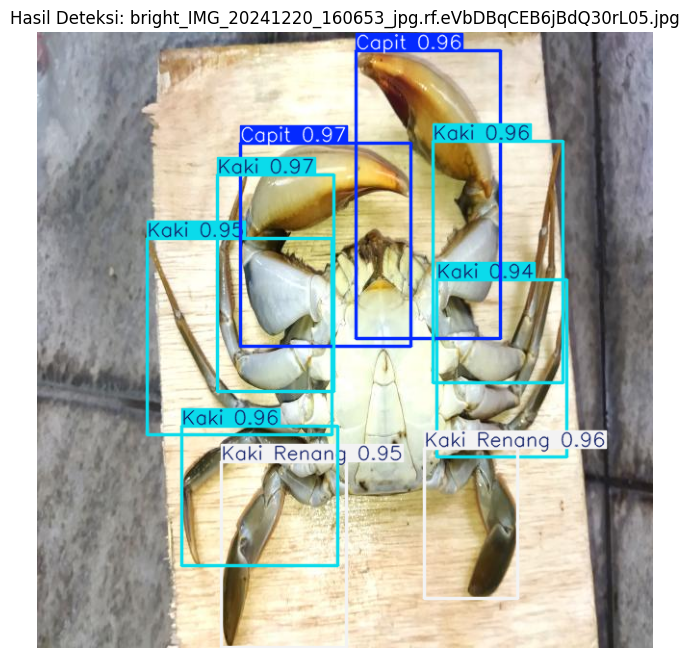

In [40]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from pathlib import Path
from ultralytics import YOLO

# 1. Pastikan file model best.pt ada
MODEL_PATH = Path("/content/crab_runs/crab_model_final/weights/best.pt")

if not MODEL_PATH.exists():
    # Jika path di atas tidak ada, gunakan best.pt di root folder
    MODEL_PATH = Path("best.pt")

if not MODEL_PATH.exists():
    raise FileNotFoundError("File best.pt tidak ditemukan! Pastikan path model sudah benar.")

model = YOLO(str(MODEL_PATH))
print("Model berhasil dimuat.")

# 2. Upload file gambar
print("\nSilakan upload foto kepiting yang ingin dideteksi:")
uploaded = files.upload()

# 3. Jalankan deteksi untuk setiap foto yang diunggah
for filename in uploaded.keys():
    print(f"\nMemproses: {filename} ...")

    # Jalankan prediksi dengan threshold confidence 0.45 & Agnostic NMS
    results = model.predict(
        source=filename,
        conf=0.45,
        iou=0.50,
        imgsz=640,
        agnostic_nms=True,
        verbose=False
    )

    res = results[0]

    # Cetak ringkasan objek yang terdeteksi
    print(f"Total bagian tubuh terdeteksi: {len(res.boxes)}")
    for i, box in enumerate(res.boxes, start=1):
        cls_id = int(box.cls[0].item())
        cls_name = model.names[cls_id]
        conf = float(box.conf[0].item())
        coords = [round(c, 1) for c in box.xyxy[0].tolist()]
        print(f"  {i}. {cls_name:12s} | Akurasi: {conf*100:.1f}% | Koordinat BBox: {coords}")

    # Visualisasikan gambar hasil deteksi
    annotated_img = cv2.cvtColor(res.plot(line_width=2, font_size=12), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img)
    plt.title(f"Hasil Deteksi: {filename}")
    plt.axis("off")
    plt.show()